# CS308 Labs 9–10 · Knowledge distillation on MNIST

Based on `cs308_lab13_teacher_student.ipynb.zip`. The lab trains a teacher, a supervised student, and a student taught through output logits. The final assignment asks for knowledge transfer between intermediate layers and a comparison with the lab's results.

| Run | Model and objective | Training schedule |
| --- | --- | --- |
| EfficientNet-B0 teacher | ImageNet-pretrained backbone with a new 10-class head, trained end to end | 30 epochs, hard labels |
| Supervised student | 1024 → 800 → 800 → 10 MLP with batch normalization and ReLU | 10 epochs, hard labels |
| Longer supervised student | The same MLP, initialized from the supervised student's best checkpoint | 30 additional epochs, hard labels |
| Logit distillation | The same MLP and starting checkpoint | 30 additional epochs, hard labels and teacher logits |
| Feature distillation | The same MLP and starting checkpoint, with a projection used in training | 30 additional epochs, hard labels and intermediate teacher features |

All five runs use the same split of the full MNIST data. We reserve 6,000 images from the 60,000 training images for checkpoint selection and use the official 10,000-image test set for final evaluation. The three continuation runs receive identical minibatch orders and use fresh Adam optimizers with the same settings.

Run all cells in a Python kernel with PyTorch, torchvision, matplotlib and pandas. CUDA is used when available. The first run downloads MNIST and torchvision's public EfficientNet-B0 checkpoint if missing from the local caches. This notebook uses torchvision's EfficientNet-B0 implementation, ImageNet normalization for the teacher, and minibatches of 128. Training uses deterministic PyTorch algorithms with a fixed seed. Hardware and software versions can still affect results.

In [1]:
import os
from copy import deepcopy
from pathlib import Path
from time import perf_counter

# Set before CUDA initializes so deterministic cuBLAS operations are available.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from torch import nn
from torchvision import __version__ as torchvision_version
from torchvision.datasets import MNIST
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0

SEED = 308
BATCH_SIZE = 128
TEACHER_EPOCHS = 30
STUDENT_EPOCHS = 10
CONTINUATION_EPOCHS = 30
TEMPERATURE = 20.0
ALPHA = 0.7
FEATURE_WEIGHT = 0.5
DATA_ROOT = Path(os.environ.get("CS308_MNIST_ROOT", "~/.cache/cs308-labs")).expanduser()

torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_cuda = device.type == "cuda"
use_bf16 = use_cuda and torch.cuda.is_bf16_supported()
torch.set_num_threads(min(torch.get_num_threads(), 8))
if use_cuda:
    torch.set_float32_matmul_precision("high")

print(f"PyTorch {torch.__version__} · torchvision {torchvision_version}")
print("Device:", torch.cuda.get_device_name() if use_cuda else "CPU")
print("Teacher training precision:", "mixed bfloat16" if use_bf16 else "float32")

PyTorch 2.11.0+cu128 · torchvision 0.26.0+cu128
Device: NVIDIA GeForce RTX 5070 Ti
Teacher training precision: mixed bfloat16


## Data and teacher

MNIST images are bilinearly resized to 32 × 32. The student takes one grayscale channel in [0, 1]. The teacher repeats it across three channels, applies ImageNet normalization, and returns ten logits. A seeded, class-stratified split assigns 600 examples per digit to validation.

In [2]:
def prepare_images(data):
    gray = data.unsqueeze(1).to(device, dtype=torch.float32).div_(255)
    return F.interpolate(gray, size=(32, 32), mode="bilinear", align_corners=False)


mnist = MNIST(DATA_ROOT, train=True, download=True)
split_rng = torch.Generator().manual_seed(SEED)
train_parts, val_parts = [], []
for digit in range(10):
    digit_ids = (mnist.targets == digit).nonzero(as_tuple=True)[0]
    digit_ids = digit_ids[torch.randperm(len(digit_ids), generator=split_rng)]
    val_parts.append(digit_ids[:600])
    train_parts.append(digit_ids[600:])

train_ids = torch.cat(train_parts)
val_ids = torch.cat(val_parts)
assert (len(train_ids), len(val_ids)) == (54_000, 6_000)
assert torch.equal(torch.cat((train_ids, val_ids)).sort().values, torch.arange(60_000))
assert torch.equal(mnist.targets[val_ids].bincount(), torch.full((10,), 600))

train_x = prepare_images(mnist.data[train_ids])
val_x = prepare_images(mnist.data[val_ids])
train_y = mnist.targets[train_ids].to(device)
val_y = mnist.targets[val_ids].to(device)

weights = EfficientNet_B0_Weights.IMAGENET1K_V1
teacher = efficientnet_b0(weights=weights, progress=False)
teacher.classifier[-1] = nn.Linear(teacher.classifier[-1].in_features, 10)
teacher = teacher.to(device=device, memory_format=torch.channels_last)
normalization = weights.transforms()
mean = torch.tensor(normalization.mean, device=device).view(1, 3, 1, 1)
std = torch.tensor(normalization.std, device=device).view(1, 3, 1, 1)


def teacher_images(gray):
    rgb = (gray - mean) / std
    return rgb.contiguous(memory_format=torch.channels_last)


def predict_teacher(gray):
    return teacher(teacher_images(gray))


print(f"Train: {len(train_y):,} · Validation: {len(val_y):,}")

Train: 54,000 · Validation: 6,000


## Training and metric calculation

Cross-entropy (CE) is the mean negative log probability of the true digit, measured in nats per image. Each minibatch contributes its **sum** of per-example losses, and the epoch denominator is the number of images processed. Accuracy is the number of correct top-1 predictions divided by the same count. Adam trains each run and `ReduceLROnPlateau` monitors validation CE. The displayed checkpoint is the epoch with the lowest validation CE.

For comparable curves, the training and validation plots show unweighted classification CE even when the optimizer also uses a distillation term.

In [3]:
@torch.no_grad()
def evaluate(predict, images, labels):
    logits = torch.cat([predict(x) for x in images.split(256)]).float()
    assert logits.shape == (len(labels), 10) and torch.isfinite(logits).all()
    correct = logits.argmax(1).eq(labels)
    return F.cross_entropy(logits, labels).item(), correct, logits


def fit(model, predict, epochs, name, transfer=None, projector=None, mixed_precision=False):
    parameters = list(model.parameters())
    if projector is not None:
        parameters.extend(projector.parameters())
    optimizer = torch.optim.Adam(parameters, lr=1e-3, fused=use_cuda)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.1, patience=5
    )
    shuffle = torch.Generator(device=device).manual_seed(SEED)
    history = []
    best_loss = float("inf")
    started = perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        totals = torch.zeros(4, device=device)
        seen = 0
        for batch in torch.randperm(len(train_y), generator=shuffle, device=device).split(BATCH_SIZE):
            xb, yb = train_x[batch], train_y[batch]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.bfloat16, enabled=mixed_precision):
                if transfer is None:
                    logits = predict(xb)
                    ce = F.cross_entropy(logits, yb)
                    penalty = ce.new_zeros(())
                    objective = ce
                else:
                    hidden = model.hidden(xb)
                    logits = model.fc3(hidden)
                    ce = F.cross_entropy(logits, yb)
                    penalty, objective = transfer(logits, hidden, ce, batch)
            objective.backward()
            if projector is not None and epoch == 1 and seen == 0:
                assert projector.weight.grad is not None
                assert torch.isfinite(projector.weight.grad).all()
                assert projector.weight.grad.norm().item() > 0
            optimizer.step()

            with torch.no_grad():
                totals += torch.stack((
                    ce.detach().float() * len(batch),
                    objective.detach().float() * len(batch),
                    penalty.detach().float() * len(batch),
                    logits.argmax(1).eq(yb).sum().float(),
                ))
            seen += len(batch)

        assert seen == len(train_y)
        train_ce, train_objective, train_penalty, train_acc = (totals / seen).tolist()
        assert torch.isfinite(totals).all()
        model.eval()
        val_ce, val_correct, _ = evaluate(predict, val_x, val_y)
        val_acc = val_correct.float().mean().item()
        lr = optimizer.param_groups[0]["lr"]
        history.append({
            "epoch": epoch, "train_ce": train_ce, "train_objective": train_objective,
            "train_penalty": train_penalty, "train_acc": train_acc, "val_ce": val_ce,
            "val_acc": val_acc, "lr": lr,
        })

        if val_ce < best_loss:
            best_loss, best_epoch = val_ce, epoch
            best_weights = deepcopy(model.state_dict())
            if projector is not None:
                best_projection = deepcopy(projector.state_dict())
        scheduler.step(val_ce)

        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(
                f"{name} {epoch:>2}/{epochs} | train CE {train_ce:.4f} | "
                f"val CE {val_ce:.4f} | val acc {val_acc:.2%} | {perf_counter() - started:.1f} s",
                flush=True,
            )

    model.load_state_dict(best_weights)
    if projector is not None:
        projector.load_state_dict(best_projection)
    model.eval()
    selected_ce, _, _ = evaluate(predict, val_x, val_y)
    assert abs(selected_ce - best_loss) < 1e-6
    print(f"Selected epoch {best_epoch} with validation CE {best_loss:.4f}.")
    return pd.DataFrame(history).set_index("epoch"), best_epoch

In [4]:
histories, best_epochs = {}, {}
teacher_name = "EfficientNet-B0 teacher"
histories[teacher_name], best_epochs[teacher_name] = fit(
    teacher, predict_teacher, TEACHER_EPOCHS, teacher_name, mixed_precision=use_bf16
)

EfficientNet-B0 teacher  1/30 | train CE 0.1865 | val CE 0.0399 | val acc 98.78% | 23.7 s


EfficientNet-B0 teacher  5/30 | train CE 0.0263 | val CE 0.0288 | val acc 99.27% | 42.8 s


EfficientNet-B0 teacher 10/30 | train CE 0.0216 | val CE 0.0308 | val acc 99.23% | 64.3 s


EfficientNet-B0 teacher 15/30 | train CE 0.0137 | val CE 0.0276 | val acc 99.27% | 86.5 s


EfficientNet-B0 teacher 20/30 | train CE 0.0112 | val CE 0.0264 | val acc 99.33% | 110.7 s


EfficientNet-B0 teacher 25/30 | train CE 0.0014 | val CE 0.0237 | val acc 99.58% | 135.3 s


EfficientNet-B0 teacher 30/30 | train CE 0.0005 | val CE 0.0298 | val acc 99.60% | 158.7 s


Selected epoch 17 with validation CE 0.0186.


## Student trained with hard labels

The MLP's second 800-unit hidden layer supplies the student representation for the intermediate-transfer experiment. Its classifier, three fully connected layers with two batch-normalization layers, is shared by all four student runs.

In [5]:
class Student(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(32 * 32, 800)
        self.bn1 = nn.BatchNorm1d(800)
        self.fc2 = nn.Linear(800, 800)
        self.bn2 = nn.BatchNorm1d(800)
        self.fc3 = nn.Linear(800, 10)

    def hidden(self, gray):
        first = F.relu(self.bn1(self.fc1(gray.flatten(1))))
        return F.relu(self.bn2(self.fc2(first)))

    def forward(self, gray):
        return self.fc3(self.hidden(gray))


torch.manual_seed(SEED)
baseline = Student().to(device)
baseline_name = "Supervised student (10 epochs)"
histories[baseline_name], best_epochs[baseline_name] = fit(
    baseline, baseline, STUDENT_EPOCHS, baseline_name
)

Supervised student (10 epochs)  1/10 | train CE 0.1677 | val CE 0.1008 | val acc 96.63% | 0.3 s


Supervised student (10 epochs)  5/10 | train CE 0.0321 | val CE 0.0612 | val acc 98.13% | 1.5 s


Supervised student (10 epochs) 10/10 | train CE 0.0174 | val CE 0.0707 | val acc 98.18% | 3.0 s


Selected epoch 8 with validation CE 0.0591.


## Frozen teacher targets

The logits encode relative class scores. The intermediate target comes from `teacher.features[5]`, the final EfficientNet stage that still produces a 2 × 2 feature map on these inputs. The 112 channels give 448 features after flattening. We cache both targets for each training image with the teacher in evaluation mode and gradients disabled. The cache follows the training indices, and the deterministic input transform means the cached targets match subsequent minibatches.

In [6]:
teacher.eval().requires_grad_(False)
teacher.zero_grad(set_to_none=True)


@torch.no_grad()
def cache_teacher_targets(images):
    logits, features = [], []
    for gray in images.split(256):
        x = teacher_images(gray)
        for index, stage in enumerate(teacher.features):
            x = stage(x)
            if index == 5:
                features.append(x.flatten(1))
        logits.append(teacher.classifier(teacher.avgpool(x).flatten(1)))
    return torch.cat(logits), torch.cat(features)


teacher_logits, teacher_features = cache_teacher_targets(train_x)
assert teacher_logits.shape == (len(train_y), 10)
assert teacher_features.shape == (len(train_y), 448)
assert not teacher_logits.requires_grad and not teacher_features.requires_grad
assert not teacher.training and all(not p.requires_grad for p in teacher.parameters())
assert torch.isfinite(teacher_features).all() and torch.isfinite(teacher_logits).all()
with torch.no_grad():
    torch.testing.assert_close(teacher_logits[:256], predict_teacher(train_x[:256]))

feature_size = teacher_features.size(1)
teacher_features = F.layer_norm(teacher_features, (feature_size,))
soft_labels = F.softmax(teacher_logits / TEMPERATURE, dim=1)
assert torch.allclose(soft_labels.sum(1), torch.ones(len(train_y), device=device))
print("Training targets — logits:", teacher_logits.shape, "| features:", teacher_features.shape)

Training targets — logits: torch.Size([54000, 10]) | features: torch.Size([54000, 448])


## Matched continuation and logit distillation

The longer supervised run controls for additional optimization from the lab's warm start. The logit-distilled student minimizes

$$
(1-\alpha)\,\mathrm{CE}(z_S,y) +
\alpha T^2\,D_{\mathrm{KL}}\!\left(
\mathrm{softmax}(z_T/T)\;\|\;\mathrm{softmax}(z_S/T)
\right).
$$

We keep the lab's temperature $T=20$ and soft-target weight $\alpha=0.7$. A high temperature makes the teacher's lower-ranked class probabilities visible to the student. The standard $T^2$ scaling compensates for shrinking gradients at high temperature. In PyTorch, `kl_div` takes the student's log probabilities first and the teacher probabilities second. `batchmean` sums over classes and divides by the number of images.

In [7]:
def logit_loss(logits, hidden, ce, batch):
    kl = F.kl_div(
        F.log_softmax(logits / TEMPERATURE, dim=1), soft_labels[batch], reduction="batchmean"
    )
    scaled_kl = TEMPERATURE**2 * kl
    return scaled_kl, (1 - ALPHA) * ce + ALPHA * scaled_kl


longer_name = "Longer supervised student"
logit_name = "Logit-distilled student"
longer = deepcopy(baseline)
distilled = deepcopy(baseline)
histories[longer_name], best_epochs[longer_name] = fit(
    longer, longer, CONTINUATION_EPOCHS, longer_name
)
histories[logit_name], best_epochs[logit_name] = fit(
    distilled, distilled, CONTINUATION_EPOCHS, logit_name, transfer=logit_loss
)

Longer supervised student  1/30 | train CE 0.0248 | val CE 0.0686 | val acc 98.22% | 0.3 s


Longer supervised student  5/30 | train CE 0.0140 | val CE 0.0575 | val acc 98.50% | 1.5 s


Longer supervised student 10/30 | train CE 0.0094 | val CE 0.0674 | val acc 98.35% | 3.0 s


Longer supervised student 15/30 | train CE 0.0006 | val CE 0.0524 | val acc 98.78% | 4.5 s


Longer supervised student 20/30 | train CE 0.0003 | val CE 0.0521 | val acc 98.90% | 5.9 s


Longer supervised student 25/30 | train CE 0.0002 | val CE 0.0533 | val acc 98.87% | 7.4 s


... (6 outputs left out)

Logit-distilled student 20/30 | train CE 0.0116 | val CE 0.0527 | val acc 98.50% | 8.3 s


Logit-distilled student 25/30 | train CE 0.0094 | val CE 0.0485 | val acc 98.60% | 10.0 s


Logit-distilled student 30/30 | train CE 0.0082 | val CE 0.0538 | val acc 98.45% | 11.7 s


Selected epoch 25 with validation CE 0.0485.


## Assignment · Intermediate feature distillation

The assignment diagram connects a teacher feature map to a projected student representation through MSE. For the supplied EfficientNet-B0 and MLP, a learned linear projection maps the student's 800-unit hidden vector into the 448-dimensional flattened teacher feature space. The objective is

$$
\mathrm{CE}(z_S,y) + 0.5\,\mathrm{MSE}\!\left(
\operatorname{LN}(W h_S + b),\;\operatorname{LN}(h_T)
\right).
$$

Here $h_S$ is the student's second hidden layer and $h_T$ is the teacher feature map. Layer normalization across each vector compares their activation patterns on a common scale. The auxiliary loss updates the projection and the upstream student layers. The student classifier receives the hard-label loss, and prediction uses the same MLP as the supervised baseline.

In [8]:
feature_name = "Feature-distilled student"
feature_student = deepcopy(baseline)
torch.manual_seed(SEED)
projector = nn.Linear(800, feature_size).to(device)


def feature_loss(logits, hidden, ce, batch):
    student_features = F.layer_norm(projector(hidden), (feature_size,))
    mse = F.mse_loss(student_features, teacher_features[batch])
    return mse, ce + FEATURE_WEIGHT * mse


histories[feature_name], best_epochs[feature_name] = fit(
    feature_student, feature_student, CONTINUATION_EPOCHS, feature_name,
    transfer=feature_loss, projector=projector,
)
assert projector.weight.grad is not None
assert all(p.grad is None for p in teacher.parameters())
print("Feature MSE per batch, averaged over images in each epoch:")
print(histories[feature_name]["train_penalty"].rename("MSE").iloc[[0, best_epochs[feature_name] - 1, -1]].round(4))

Feature-distilled student  1/30 | train CE 0.0216 | val CE 0.0627 | val acc 98.32% | 1.6 s


Feature-distilled student  5/30 | train CE 0.0096 | val CE 0.0573 | val acc 98.53% | 3.1 s


Feature-distilled student 10/30 | train CE 0.0093 | val CE 0.0607 | val acc 98.33% | 5.0 s


Feature-distilled student 15/30 | train CE 0.0048 | val CE 0.0514 | val acc 98.75% | 6.8 s


Feature-distilled student 20/30 | train CE 0.0017 | val CE 0.0590 | val acc 98.72% | 8.8 s


Feature-distilled student 25/30 | train CE 0.0009 | val CE 0.0382 | val acc 99.12% | 10.7 s


Feature-distilled student 30/30 | train CE 0.0013 | val CE 0.0489 | val acc 98.82% | 12.6 s


Selected epoch 25 with validation CE 0.0382.
Feature MSE per batch, averaged over images in each epoch:
epoch
1     0.2221
25    0.0777
30    0.0761
Name: MSE, dtype: float64


## Learning curves

The teacher and baseline use their own epoch numbering. The three continuation curves share a starting checkpoint. Dots mark the validation CE checkpoint used for test evaluation.

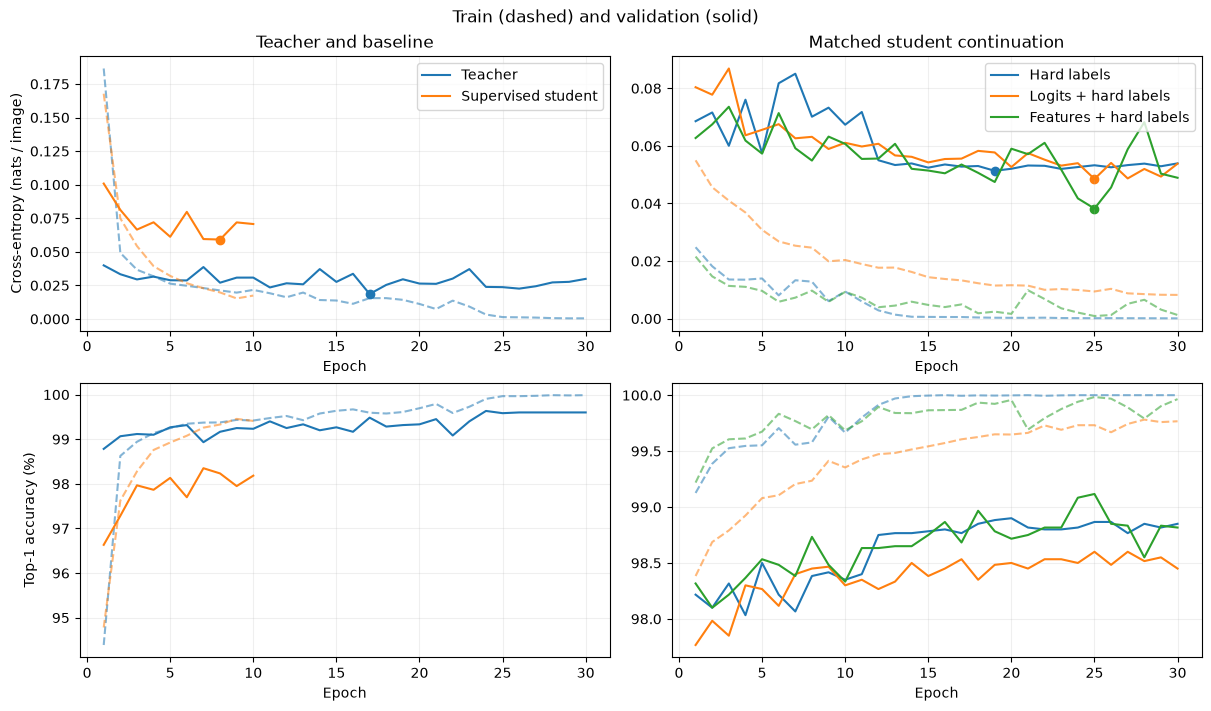

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
groups = ([teacher_name, baseline_name], [longer_name, logit_name, feature_name])
short_name = {
    teacher_name: "Teacher", baseline_name: "Supervised student",
    longer_name: "Hard labels", logit_name: "Logits + hard labels",
    feature_name: "Features + hard labels",
}

for col, names in enumerate(groups):
    for name in names:
        history = histories[name]
        (line,) = axes[0, col].plot(history.index, history.val_ce, label=short_name[name])
        color = line.get_color()
        axes[0, col].plot(history.index, history.train_ce, "--", color=color, alpha=0.55)
        axes[0, col].scatter(best_epochs[name], history.loc[best_epochs[name], "val_ce"], color=color)
        axes[1, col].plot(history.index, history.val_acc * 100, label=short_name[name], color=color)
        axes[1, col].plot(history.index, history.train_acc * 100, "--", color=color, alpha=0.55)
    axes[0, col].set_title(("Teacher and baseline", "Matched student continuation")[col])
    axes[0, col].set_xlabel("Epoch")
    axes[1, col].set_xlabel("Epoch")
    axes[0, col].legend()
    for ax in axes[:, col]:
        ax.grid(alpha=0.2)

axes[0, 0].set_ylabel("Cross-entropy (nats / image)")
axes[1, 0].set_ylabel("Top-1 accuracy (%)")
fig.suptitle("Train (dashed) and validation (solid)")
plt.show()

## Held-out test results

The table reports the official MNIST test accuracy and CE for the selected checkpoint in each run. The original notebook's reported accuracies are included as historical references. It reused the test data for validation, divided a sum of minibatch means by the image count, and overwrote the distillation training-accuracy count instead of accumulating it. Its loss numbers therefore have a different scale and its reported accuracies come from a different evaluation protocol. The original logit objective also scaled the default KL mean across both examples and classes by `T*T*2.0 + alpha`. For ten classes, that corresponds to a multiplier of 80.07 on per-image KL, while the standard objective used here gives 280. Both objectives weight hard-label CE by 0.3.

In [10]:
test = MNIST(DATA_ROOT, train=False, download=True)
test_x = prepare_images(test.data)
test_y = test.targets.to(device)
assert len(test_y) == 10_000

predictors = {
    teacher_name: predict_teacher,
    baseline_name: baseline,
    longer_name: longer,
    logit_name: distilled,
    feature_name: feature_student,
}
lab_accuracy_pct = {teacher_name: 99.39, baseline_name: 98.35, logit_name: 98.79}
rows, correctness = [], {}

for name, predictor in predictors.items():
    test_ce, correct, logits = evaluate(predictor, test_x, test_y)
    independent_ce = -logits.log_softmax(1).gather(1, test_y[:, None]).mean().item()
    assert abs(test_ce - independent_ce) < 1e-6
    confusion = torch.bincount(test_y * 10 + logits.argmax(1), minlength=100).reshape(10, 10)
    n_correct = int(correct.sum().item())
    assert confusion.sum().item() == 10_000 and confusion.trace().item() == n_correct
    correctness[name] = correct
    rows.append({
        "Model": name,
        "Selected epoch": best_epochs[name],
        "Validation CE": histories[name].loc[best_epochs[name], "val_ce"],
        "Test correct": n_correct,
        "Test accuracy (%)": 100 * n_correct / len(test_y),
        "Test CE": test_ce,
        "Source accuracy (%)": lab_accuracy_pct.get(name),
    })

results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,Selected epoch,Validation CE,Test correct,Test accuracy (%),Test CE,Source accuracy (%)
Model,,,,,,
EfficientNet-B0 teacher,17,0.0186,9934,99.34,0.0257,99.39
Supervised student (10 epochs),8,0.0591,9836,98.36,0.0549,98.35
Longer supervised student,19,0.0513,9879,98.79,0.0478,NaN
Logit-distilled student,25,0.0485,9847,98.47,0.0556,98.79
Feature-distilled student,25,0.0382,9911,99.11,0.0417,NaN


In [11]:
teacher_params = sum(p.numel() for p in teacher.parameters())
student_params = sum(p.numel() for p in feature_student.parameters())
projection_params = sum(p.numel() for p in projector.parameters())
assert all(
    sum(p.numel() for p in student_model.parameters()) == student_params
    for student_model in (baseline, longer, distilled)
)
accuracy = results["Test accuracy (%)"]


def compare(name, reference):
    new = correctness[name]
    old = correctness[reference]
    fixed = (new & ~old).sum().item()
    lost = (~new & old).sum().item()
    delta = 100 * (fixed - lost) / len(test_y)
    assert abs(delta - (accuracy[name] - accuracy[reference])) < 1e-9
    return f"{delta:+.2f} percentage points ({fixed} corrected, {lost} newly missed)"


feature_ce_delta = results.loc[feature_name, "Test CE"] - results.loc[longer_name, "Test CE"]
display(Markdown(
    f"- The EfficientNet teacher scored **{accuracy[teacher_name]:.2f}%** "
    f"with **{teacher_params:,}** parameters. Each student uses **{student_params:,}** "
    f"parameters at inference ({student_params / teacher_params:.1%} of the teacher’s count). "
    f"Feature training adds a **{projection_params:,}**-parameter projection.\n"
    f"- Longer supervised training versus the 10-epoch student: "
    f"**{compare(longer_name, baseline_name)}**.\n"
    f"- Logit distillation versus the longer supervised control: "
    f"**{compare(logit_name, longer_name)}**.\n"
    f"- Feature distillation versus the longer supervised control: "
    f"**{compare(feature_name, longer_name)}**. The feature run's test CE changed by "
    f"**{feature_ce_delta:+.4f} nats per image**. Accuracy depends on the predicted "
    f"class, while CE also reflects how much probability the model gave the true label.\n"
    f"- Feature distillation versus this notebook's logit student: "
    f"**{compare(feature_name, logit_name)}**. The source reported "
    f"**{lab_accuracy_pct[logit_name]:.2f}%** for its taught student. This feature run "
    f"scored **{accuracy[feature_name]:.2f}%**, a difference of "
    f"**{accuracy[feature_name] - lab_accuracy_pct[logit_name]:+.2f} percentage points** "
    f"under the protocol described above.\n\n"
    "These results describe one seeded split and training run. "
    "They measure the chosen feature layer, projection, and loss weight."
))

- The EfficientNet teacher scored **99.34%** with **4,020,358** parameters. Each student uses **1,472,010** parameters at inference (36.6% of the teacher’s count). Feature training adds a **358,848**-parameter projection.
- Longer supervised training versus the 10-epoch student: **+0.43 percentage points (72 corrected, 29 newly missed)**.
- Logit distillation versus the longer supervised control: **-0.32 percentage points (50 corrected, 82 newly missed)**.
- Feature distillation versus the longer supervised control: **+0.32 percentage points (50 corrected, 18 newly missed)**. The feature run's test CE changed by **-0.0061 nats per image**. Accuracy depends on the predicted class, while CE also reflects how much probability the model gave the true label.
- Feature distillation versus this notebook's logit student: **+0.64 percentage points (93 corrected, 29 newly missed)**. The source reported **98.79%** for its taught student. This feature run scored **99.11%**, a difference of **+0.32 percentage points** under the protocol described above.

These results describe one seeded split and training run. They measure the chosen feature layer, projection, and loss weight.